##  La théorie : Le modèle SIR classique

### Contexte
Le modèle SIR a été développé initialement pour les épidémies (Kermack-McKendrick, 1927), mais il s'applique parfaitement à la propagation de rumeurs sur les réseaux sociaux.

### Les trois états
- **S (Susceptible)** : Personnes qui n'ont pas encore entendu la rumeur
- **I (Infected)** : Personnes qui propagent activement la rumeur
- **R (Recovered)** : Personnes qui ont rejeté/oublié la rumeur

### Le système d'équations différentielles

$$
\begin{cases}
\frac{dS}{dt} = -\beta \frac{SI}{N} \\
\frac{dI}{dt} = \beta \frac{SI}{N} - \gamma I \\
\frac{dR}{dt} = \gamma I
\end{cases}
$$

**Paramètres :**
- $\beta$ = taux de transmission (combien de personnes un infecté contamine par unité de temps)
- $\gamma$ = taux de récupération (vitesse à laquelle les infectés arrêtent de propager)
- $N$ = population totale ($S + I + R = N$)

### Interprétation des équations

1. **$\frac{dS}{dt} = -\beta \frac{SI}{N}$** : Les susceptibles diminuent proportionnellement aux contacts entre S et I

2. **$\frac{dI}{dt} = \beta \frac{SI}{N} - \gamma I$** : Les infectés augmentent par contamination et diminuent par rejet

3. **$\frac{dR}{dt} = \gamma I$** : Les recovered augmentent proportionnellement aux infectés qui rejettent

## Simulation stochastique sur réseau

### Pourquoi cette méthode ?

Les réseaux sociaux ont une **structure particulière** :
- Certaines personnes ont beaucoup d'amis (hubs)
- D'autres ont peu de connexions
- Les contacts ne sont pas uniformes
- Il y a de l'aléatoire dans la propagation

### Principe : Agent-Based Model (ABM)

Au lieu de suivre des populations globales S(t), I(t), R(t), on suit **chaque individu** séparément.

### Étapes de la transformation théorie → code

## Étape 1 : Discrétisation du temps

### Théorie (temps continu)
$$\frac{dI}{dt} = \beta \frac{SI}{N} - \gamma I$$

### Pratique (temps discret)
On remplace le temps continu $t$ par des pas de temps $t = 0, 1, 2, 3, ..., T$

À chaque pas de temps, on met à jour l'état de tous les nœuds.

**Correspondance :**
- Un pas de temps = une unité de temps arbitraire (par exemple, 1 heure, 1 jour...)
- On itère sur `frames` (étapes)

## Étape 2 : Modélisation sur un réseau

### Théorie
Le terme $\beta \frac{SI}{N}$ suppose que **tout le monde peut rencontrer tout le monde** avec la même probabilité.

### Pratique
On crée un **graphe** où :
- Chaque **nœud** = une personne
- Chaque **arête** = une connexion sociale (ami, follower...)
- La rumeur se propage **uniquement entre voisins connectés**

### Type de réseau : Barabási-Albert

```python
G = nx.barabasi_albert_graph(N, 2)
```

Ce réseau a une propriété **scale-free** :
- Quelques nœuds ont beaucoup de connexions (influenceurs)
- La plupart ont peu de connexions
- **Réaliste pour les réseaux sociaux** (Twitter, Facebook...)

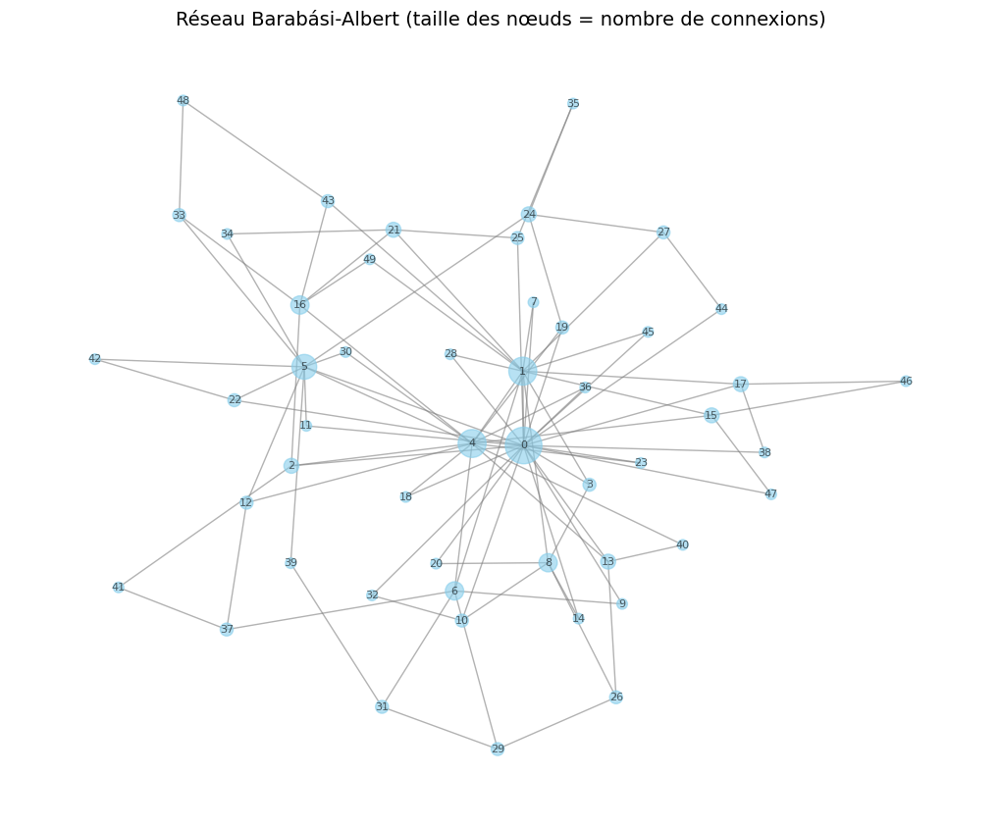

Nombre de nœuds : 50
Nombre d'arêtes : 96
Degré moyen : 3.84
Nœud le plus connecté : 0 avec 24 connexions


In [5]:
import networkx as nx
import matplotlib.pyplot as plt

# Création du réseau
G = nx.barabasi_albert_graph(50, 2, seed=42)
pos = nx.spring_layout(G, seed=42)

# Calcul du degré de chaque nœud (nombre de connexions)
degrees = dict(G.degree())
node_sizes = [degrees[node] * 30 for node in G.nodes()]

# Visualisation
plt.figure(figsize=(10, 8))
nx.draw(G, pos, node_size=node_sizes, node_color='skyblue', 
        with_labels=True, font_size=8, edge_color='gray', alpha=0.6)
plt.title('Réseau Barabási-Albert (taille des nœuds = nombre de connexions)', fontsize=14)
plt.show()

print(f"Nombre de nœuds : {G.number_of_nodes()}")
print(f"Nombre d'arêtes : {G.number_of_edges()}")
print(f"Degré moyen : {sum(degrees.values()) / len(degrees):.2f}")
print(f"Nœud le plus connecté : {max(degrees, key=degrees.get)} avec {max(degrees.values())} connexions")

##  Étape 3 : Conversion des taux en probabilités

### Théorie : Taux continus
- $\beta$ = taux de transmission (nombre de contaminations par unité de temps)
- $\gamma$ = taux de récupération

### Pratique : Probabilités discrètes

#### **Règle 1 : Propagation** (S → I)

**Théorie :**  
Un susceptible $S$ devient infecté avec un taux $\beta I / N$

**Pratique :**  
À chaque pas de temps, pour chaque nœud infecté $i$ :
- On parcourt ses voisins $j$
- Si $j$ est susceptible, il devient infecté avec probabilité $\beta$

```python
for neighbor in G.neighbors(infected_node):
    if state[neighbor] == 'S':
        if random.random() < beta:  # Tirage aléatoire
            new_state[neighbor] = 'I'
```

#### **Règle 2 : Rejet** (I → R)

**Théorie :**  
Un infecté $I$ devient recovered avec un taux $\gamma$

**Pratique :**  
À chaque pas de temps, chaque nœud infecté a une probabilité $\gamma$ de rejeter la rumeur

```python
if state[node] == 'I':
    if random.random() < gamma:  # Tirage aléatoire
        new_state[node] = 'R'
```

##  Étape 4 : L'algorithme complet

### Pseudo-code

```
INITIALISATION:
1. Créer un réseau G avec N nœuds
2. Initialiser tous les nœuds à 'S' (susceptible)
3. Sélectionner aléatoirement k nœuds initiaux et les mettre à 'I' (infectés)

POUR chaque pas de temps t = 0, 1, 2, ..., T:
    
    new_state = copie de state  # Pour mise à jour synchrone
    
    POUR chaque nœud i dans G:
        
        SI state[i] == 'I':  # Le nœud est infecté
            
            # Règle 1: Propagation aux voisins
            POUR chaque voisin j de i:
                SI state[j] == 'S':  # Le voisin est susceptible
                    SI random() < beta:  # Transmission avec probabilité beta
                        new_state[j] = 'I'
            
            # Règle 2: Rejet de la rumeur
            SI random() < gamma:  # Rejet avec probabilité gamma
                new_state[i] = 'R'
    
    state = new_state  # Mise à jour synchrone
    
    # Visualisation de l'état actuel
    afficher(G, state)
```

## Implémentation complète

In [6]:
import networkx as nx
import random
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
import numpy as np

# Configuration pour VS Code notebooks
plt.rcParams['animation.html'] = 'jshtml'

# ----------------------------
# Paramètres du modèle
# ----------------------------
N =50              # nombre de nœuds
beta = 0.3          # probabilité de transmission
gamma = 0.1         # probabilité de rejet
initial_infected = 2


In [7]:
# ----------------------------
# Création du réseau
# ----------------------------
G = nx.barabasi_albert_graph(N, 2, seed=42)
pos = nx.spring_layout(G, seed=42)

# États des nœuds : S (Susceptible), I (Infected), R (Recovered)
state = {node: 'S' for node in G.nodes()}
random.seed(42)
initial_nodes = random.sample(list(G.nodes()), initial_infected)
for node in initial_nodes:
    state[node] = 'I'

# Historique pour statistiques
history = {'S': [], 'I': [], 'R': []}

# ----------------------------
# Fonction de mise à jour
# ----------------------------
def update(frame):
    global state
    
    new_state = state.copy()

    for node in G.nodes():
        if state[node] == 'I':
            # Propagation vers les voisins susceptibles
            for neighbor in G.neighbors(node):
                if state[neighbor] == 'S':
                    if random.random() < beta:
                        new_state[neighbor] = 'I'
            # Rejet (recovery)
            if random.random() < gamma:
                new_state[node] = 'R'

    # Mise à jour complète des états
    state = new_state.copy()

    # Calcul des statistiques
    counts = {'S': 0, 'I': 0, 'R': 0}
    color_map = []
    
    for node in G.nodes():
        counts[state[node]] += 1
        if state[node] == 'S':
            color_map.append('dodgerblue')
        elif state[node] == 'I':
            color_map.append('red')
        else:
            color_map.append('limegreen')
    
    # Enregistrement de l'historique
    history['S'].append(counts['S'])
    history['I'].append(counts['I'])
    history['R'].append(counts['R'])

    # Effacer la figure
    plt.clf()
    
    # Sous-graphique pour le réseau
    ax1 = plt.subplot(1, 2, 1)
    nx.draw(G, pos, node_color=color_map, with_labels=False, 
            node_size=150, ax=ax1, edge_color='gray', alpha=0.6)
    ax1.set_title(f"Propagation de la rumeur – Étape {frame}", fontsize=12, fontweight='bold')
    
    # Sous-graphique pour les statistiques
    ax2 = plt.subplot(1, 2, 2)
    frames_list = list(range(len(history['S'])))
    ax2.plot(frames_list, history['S'], 'dodgerblue', linewidth=2, label='Susceptible')
    ax2.plot(frames_list, history['I'], 'red', linewidth=2, label='Infecté (rumeur)')
    ax2.plot(frames_list, history['R'], 'limegreen', linewidth=2, label='Recovered (rejeté)')
    ax2.set_xlabel('Temps', fontsize=10)
    ax2.set_ylabel('Nombre de nœuds', fontsize=10)
    ax2.set_title('Évolution temporelle', fontsize=12, fontweight='bold')
    ax2.legend(loc='best', fontsize=8)
    ax2.grid(True, alpha=0.3)
    ax2.set_xlim(0, 100)
    ax2.set_ylim(0, N)
    
    # Affichage des compteurs
    textstr = f'S: {counts["S"]}  |  I: {counts["I"]}  |  R: {counts["R"]}'
    plt.figtext(0.5, 0.02, textstr, ha='center', fontsize=11, 
                bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))


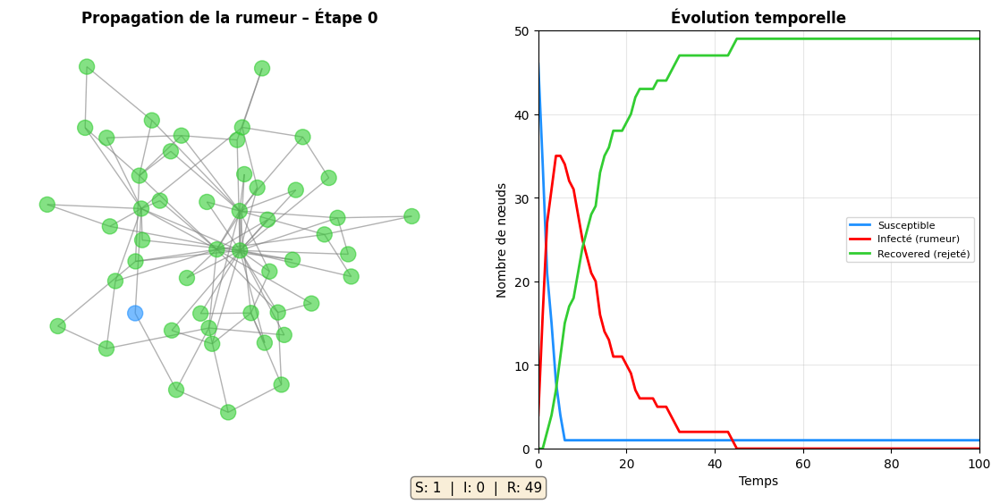

In [8]:
# ----------------------------
# Animation
# ----------------------------
fig = plt.figure(figsize=(14, 6))
plt.subplots_adjust(bottom=0.1)

anim = FuncAnimation(fig, update, frames=100, interval=300, repeat=False)
plt.tight_layout()

# Afficher l'animation dans le notebook
HTML(anim.to_jshtml())